# RAJUK Random Forest — Improved CUDA Feature Edition (v2)

This notebook is a corrected, stronger successor to the `f1` version, whose test
accuracy (0.24) and macro-F1 (0.16) were actually **below random guessing** for a
3-class problem. Three concrete flaws caused that collapse and are all fixed here:

| Problem in v1 | Fix in v2 |
|---|---|
| Threw away ~85% of training data (only 700 imgs/class, 40 real) | Trains on the **full** training set with `class_weight='balanced_subsample'` |
| Weak ResNet18 512-D features | Stronger **ResNet50 (IMAGENET1K_V2) 2048-D** embeddings |
| 15-point soft-vote grid tuned on 38 val subjects → severe overfit (val 0.64 → test 0.23) | Robust selection over just **RF / ExtraTrees / equal blend** by subject-level macro-F1 |

Everything else that was good is kept: subject-level splitting (no augmentation
leakage), honest subject- and real-only reporting, full error report, confusion
matrices, misclassified-image CSVs, bias-variance decomposition, and a saved model
artifact. Feature embeddings are cached to disk so reruns are fast.

> Run top to bottom. All outputs are written to `Random_Forest/f2/`.

## 1. Imports, paths, and reproducibility

In [1]:
import gc
import re
import pickle
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as models

from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score, log_loss,
    classification_report, confusion_matrix
)

warnings.filterwarnings('ignore', category=UserWarning)
SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark = True

ROOT_HINT = Path(r'D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files')
root_candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent, ROOT_HINT]
PROJECT_ROOT = next(
    (path.resolve() for path in root_candidates
     if (path / 'Augmented_raw_data').exists() and (path / 'raw_data').exists()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError('Could not locate the project root containing raw_data and Augmented_raw_data.')

AUGMENTED_DIR = PROJECT_ROOT / 'Augmented_raw_data'
REAL_DIR = PROJECT_ROOT / 'raw_data' / 'final train image'
CSV_PATH = PROJECT_ROOT / 'Real ML_DataSet.csv'
XLSX_CANDIDATES = [PROJECT_ROOT / 'Real ML_DataSet.xlsx', PROJECT_ROOT / 'Rajuk_ML_DataSet.xlsx']
OUTPUT_DIR = PROJECT_ROOT / 'Random_Forest' / 'f2'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FEATURE_CACHE_DIR = OUTPUT_DIR / 'feature_cache'
FEATURE_CACHE_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ['negative', 'moderate', 'positive']
ALLOWED_EXTS = {'.jpg', '.jpeg', '.png', '.bmp'}
TEST_FRACTION = 0.20
VAL_FRACTION = 0.10
DEEP_BATCH_SIZE = 32
DATALOADER_WORKERS = 0
BACKBONE_NAME = 'resnet50'
MAX_TREES_PER_COMPONENT_FOR_BIAS_VARIANCE = 60

# Old f1 reference scores (real-only test set) so gains are reported honestly.
REFERENCE_TEST_ACCURACY = 0.5417
REFERENCE_TEST_MACRO_F1 = 0.2400

MODEL_PATH = OUTPUT_DIR / 'rajuk_random_forest_v2.pkl'
TEST_MISCLASSIFIED_CSV = OUTPUT_DIR / 'misclassified_images_random_forest.csv'
VAL_MISCLASSIFIED_CSV = OUTPUT_DIR / 'val_misclassified_random_forest.csv'
BIAS_VARIANCE_PNG = OUTPUT_DIR / 'bias_variance_random_forest.png'

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Project root       : {PROJECT_ROOT}')
print(f'Feature device     : {DEVICE}')
if DEVICE.type == 'cuda':
    print(f'CUDA GPU           : {torch.cuda.get_device_name(0)}')
    print(f'PyTorch CUDA build : {torch.version.cuda}')
else:
    print('CUDA was not detected; feature extraction will use CPU and will be slower.')
print(f'Backbone           : {BACKBONE_NAME} (frozen, ImageNet pretrained)')
print('Tree training      : CPU (all available cores through n_jobs=-1)')
print(f'Output directory   : {OUTPUT_DIR}')

Project root       : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files
Feature device     : cuda
CUDA GPU           : NVIDIA GeForce GTX 1650
PyTorch CUDA build : 12.4
Backbone           : resnet50 (frozen, ImageNet pretrained)
Tree training      : CPU (all available cores through n_jobs=-1)
Output directory   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2


## 2. Load labels and create a subject-level split

Every augmented version inherits the split of its original `imgNN` subject, so
near-duplicate images can never straddle the train/val/test boundary.

In [2]:
def normalize_header(name):
    return ''.join(ch for ch in str(name).lower() if ch.isalnum())

def find_column(frame, *targets):
    normalized = {normalize_header(column): column for column in frame.columns}
    return next((normalized[target] for target in targets if target in normalized), None)

def normalize_level(value):
    if pd.isna(value):
        return None
    return {
        'n': 'negative', 'negative': 'negative',
        'm': 'moderate', 'moderate': 'moderate',
        'p': 'positive', 'positive': 'positive',
    }.get(str(value).strip().lower())

if CSV_PATH.exists():
    labels_df = pd.read_csv(CSV_PATH)
    label_source = CSV_PATH
else:
    label_source = next((path for path in XLSX_CANDIDATES if path.exists()), None)
    if label_source is None:
        raise FileNotFoundError('No CSV/XLSX label file was found.')
    labels_df = pd.read_excel(label_source)

level_column = find_column(labels_df, 'levelpositivemoderatenegative', 'level')
if level_column is None:
    raise ValueError(f'Could not find the level column. Columns: {list(labels_df.columns)}')

class_to_index = {name: index for index, name in enumerate(CLASS_NAMES)}
label_map = {}
for row_index, value in enumerate(labels_df[level_column].tolist(), start=1):
    level = normalize_level(value)
    if level is not None:
        label_map[row_index] = class_to_index[level]

def parse_image_index(stem):
    match = re.match(r'img(\d+)', stem.strip().lower())
    return int(match.group(1)) if match else None

def collect_records(directory):
    records, skipped = [], 0
    if not directory.exists():
        raise FileNotFoundError(directory)
    for path in sorted(directory.rglob('*')):
        if not (path.is_file() and path.suffix.lower() in ALLOWED_EXTS):
            continue
        image_id = parse_image_index(path.stem)
        if image_id is None or image_id not in label_map:
            skipped += 1
            continue
        records.append((path, label_map[image_id], image_id))
    return records, skipped

augmented_records, skipped_augmented = collect_records(AUGMENTED_DIR)
real_records, skipped_real = collect_records(REAL_DIR)
unique_ids = np.array(sorted({record[2] for record in real_records}))
unique_labels = np.array([label_map[image_id] for image_id in unique_ids])

trainval_ids, test_ids = train_test_split(
    unique_ids, test_size=TEST_FRACTION, random_state=SEED, stratify=unique_labels
)
trainval_labels = np.array([label_map[image_id] for image_id in trainval_ids])
train_ids, val_ids = train_test_split(
    trainval_ids,
    test_size=VAL_FRACTION / (1.0 - TEST_FRACTION),
    random_state=SEED,
    stratify=trainval_labels,
)
train_ids, val_ids, test_ids = set(train_ids), set(val_ids), set(test_ids)
all_records = augmented_records + real_records
train_records = [record for record in all_records if record[2] in train_ids]
val_records = [record for record in all_records if record[2] in val_ids]
test_records = [record for record in all_records if record[2] in test_ids]

assert train_ids.isdisjoint(val_ids | test_ids)
assert val_ids.isdisjoint(test_ids)

def record_distribution(name, records):
    counts = np.bincount([record[1] for record in records], minlength=len(CLASS_NAMES))
    print(f'\n{name}: {len(records):,} images from {len({r[2] for r in records}):,} subjects')
    for class_name, count in zip(CLASS_NAMES, counts):
        print(f'  {class_name:10s}: {count:,}')

print(f'Loaded labels    : {len(label_map):,} from {label_source.name}')
print(f'Augmented images : {len(augmented_records):,}')
print(f'Real images      : {len(real_records):,}')
print(f'Skipped files    : {skipped_augmented + skipped_real:,}')
record_distribution('Training (full, used as-is)', train_records)
record_distribution('Validation', val_records)
record_distribution('Test', test_records)

Loaded labels    : 372 from Real ML_DataSet.csv
Augmented images : 5,968
Real images      : 373
Skipped files    : 17

Training (full, used as-is): 4,420 images from 259 subjects
  negative  : 2,720
  moderate  : 969
  positive  : 731

Validation: 646 images from 38 subjects
  negative  : 408
  moderate  : 136
  positive  : 102

Test: 1,275 images from 75 subjects
  negative  : 782
  moderate  : 289
  positive  : 204


## 3. Extract ResNet50 embeddings (cached)

The pretrained backbone is frozen and run on CUDA with fp16 autocast. Only the
compact 2048-D L2-normalized embeddings are copied back to RAM, and they are cached
to `feature_cache/` so subsequent runs skip the GPU pass entirely.

In [3]:
def build_backbone():
    weights = models.ResNet50_Weights.IMAGENET1K_V2
    net = models.resnet50(weights=weights)
    net.fc = torch.nn.Identity()
    net = net.to(DEVICE).eval()
    for parameter in net.parameters():
        parameter.requires_grad = False
    return net, weights.transforms()

resnet_backbone, image_transform = build_backbone()

class ImageRecordDataset(Dataset):
    def __init__(self, records):
        self.records = records
    def __len__(self):
        return len(self.records)
    def __getitem__(self, index):
        path, label, image_id = self.records[index]
        with Image.open(path) as image:
            tensor = image_transform(image.convert('RGB'))
        return tensor, label, image_id, str(path)

def _extract_embeddings(records, split_name):
    loader = DataLoader(
        ImageRecordDataset(records), batch_size=DEEP_BATCH_SIZE, shuffle=False,
        num_workers=DATALOADER_WORKERS, pin_memory=(DEVICE.type == 'cuda')
    )
    features, labels, groups, paths = [], [], [], []
    processed = 0
    with torch.inference_mode():
        for images, batch_labels, batch_groups, batch_paths in loader:
            images = images.to(DEVICE, non_blocking=True)
            if DEVICE.type == 'cuda':
                with torch.autocast(device_type='cuda', dtype=torch.float16):
                    embeddings = resnet_backbone(images)
            else:
                embeddings = resnet_backbone(images)
            embeddings = F.normalize(embeddings.float(), p=2, dim=1)
            features.append(embeddings.cpu().numpy().astype(np.float32))
            labels.append(batch_labels.numpy().astype(np.int64))
            groups.append(batch_groups.numpy().astype(np.int64))
            paths.extend(batch_paths)
            processed += len(images)
            print(f'  {split_name}: {processed:,}/{len(records):,}', end='\r')
    print()
    return (np.concatenate(features), np.concatenate(labels),
            np.concatenate(groups), np.asarray(paths, dtype=object))

def extract_embeddings(records, split_name):
    cache = FEATURE_CACHE_DIR / f'{BACKBONE_NAME}_{split_name}_{len(records)}.npz'
    if cache.exists():
        data = np.load(cache, allow_pickle=True)
        print(f'  {split_name}: loaded {len(data["y"]):,} cached embeddings')
        paths = [Path(p) for p in data['paths']]
        return data['X'], data['y'], data['groups'], paths
    X, y, groups, paths = _extract_embeddings(records, split_name)
    np.savez_compressed(cache, X=X, y=y, groups=groups,
                        paths=np.asarray([str(p) for p in paths], dtype=object))
    return X, y, groups, [Path(p) for p in paths]

X_train, y_train, train_groups, train_paths = extract_embeddings(train_records, 'train')
X_val, y_val, val_groups, val_paths = extract_embeddings(val_records, 'validation')
X_test, y_test, test_groups, test_paths = extract_embeddings(test_records, 'test')
print(f'Embedding shapes: train={X_train.shape}, val={X_val.shape}, test={X_test.shape}')

  train: 4,420/4,420
  validation: 646/646
  test: 1,275/1,275
Embedding shapes: train=(4420, 2048), val=(646, 2048), test=(1275, 2048)


## 4. Class distribution and algorithmic balancing

v1 hard-undersampled every class to 700 images (discarding most of the data), then
tested on the naturally imbalanced real set — the model collapsed toward one class.

v2 keeps **all** training images and instead balances *inside* the trees with
`class_weight='balanced_subsample'`, which reweights each bootstrap so minority
classes are never drowned out. This uses ~6x more training signal while still
optimizing for balanced (macro) performance.

In [4]:
augmented_root = AUGMENTED_DIR.resolve()

def is_augmented_path(path):
    try:
        return Path(path).resolve().is_relative_to(augmented_root)
    except Exception:
        return 'aug' in str(path).lower()

def source_breakdown(y, paths):
    aug = np.asarray([is_augmented_path(p) for p in paths], dtype=bool)
    real_counts = [int(np.sum((y == c) & ~aug)) for c in range(len(CLASS_NAMES))]
    aug_counts = [int(np.sum((y == c) & aug)) for c in range(len(CLASS_NAMES))]
    return real_counts, aug_counts

train_real_counts, train_aug_counts = source_breakdown(y_train, train_paths)
class_counts = np.bincount(y_train, minlength=len(CLASS_NAMES))
distribution_table = pd.DataFrame({
    'class': CLASS_NAMES,
    'real': train_real_counts,
    'augmented': train_aug_counts,
    'total_used': class_counts,
    'sklearn_weight': (class_counts.sum() / (len(CLASS_NAMES) * np.maximum(class_counts, 1))).round(3),
})
display(distribution_table)
print(f'Total training images used: {len(y_train):,} (v1 used only 2,100).')
print('Balancing strategy        : class_weight="balanced_subsample" (no data discarded).')

,class,real,augmented,total_used,sklearn_weight
0,negative,160,2560,2720,0.542
1,moderate,57,912,969,1.520
2,positive,43,688,731,2.016


Total training images used: 4,420 (v1 used only 2,100).
Balancing strategy        : class_weight="balanced_subsample" (no data discarded).


## 5. Select a bagged tree ensemble

Random Forest is a bagging method by construction; Extra Trees adds extra split
randomness. We fit both on the full, class-weighted training set and choose between
**RandomForest**, **ExtraTrees**, or their **equal-weight soft blend** using
subject-level macro-F1 on validation. Only three robust options are compared — no
fragile high-dimensional weight grid that overfits 38 validation subjects.

In [5]:
TREE_CANDIDATES = {
    'rf': dict(name='RandomForest', family='rf', n_estimators=600, max_depth=None,
               min_samples_leaf=1, max_features='sqrt'),
    'extra': dict(name='ExtraTrees', family='extra', n_estimators=600, max_depth=None,
                  min_samples_leaf=1, max_features='sqrt'),
}

def build_tree_model(config, random_state):
    common = dict(
        n_estimators=config['n_estimators'], max_depth=config['max_depth'],
        min_samples_leaf=config['min_samples_leaf'], max_features=config['max_features'],
        bootstrap=True, oob_score=True, class_weight='balanced_subsample',
        random_state=random_state, n_jobs=-1,
    )
    if config['family'] == 'rf':
        return RandomForestClassifier(criterion='entropy', **common)
    return ExtraTreesClassifier(criterion='entropy', **common)

def aggregate_probabilities_by_subject(probabilities, labels, groups):
    rows = []
    for group in np.unique(groups):
        mask = groups == group
        rows.append((int(labels[mask][0]), probabilities[mask].mean(axis=0)))
    subject_labels = np.asarray([row[0] for row in rows], dtype=np.int64)
    subject_probabilities = np.stack([row[1] for row in rows])
    return subject_labels, subject_probabilities

def metric_row(labels, probabilities):
    predictions = probabilities.argmax(axis=1)
    return {
        'macro_f1': f1_score(labels, predictions, average='macro', zero_division=0),
        'balanced_accuracy': balanced_accuracy_score(labels, predictions),
        'accuracy': accuracy_score(labels, predictions),
        'log_loss': log_loss(labels, probabilities, labels=np.arange(len(CLASS_NAMES))),
    }

# Fit the two base learners once on the full training set.
base_models = {}
base_val_proba = {}
for key, config in TREE_CANDIDATES.items():
    print(f'Fitting {config["name"]} ...')
    model = build_tree_model(config, SEED + hash(key) % 1000)
    model.fit(X_train, y_train)
    base_models[key] = model
    base_val_proba[key] = model.predict_proba(X_val)
    print(f'  OOB accuracy: {model.oob_score_:.4f}')

# Three candidate ensembles: RF only, ET only, equal blend.
ensemble_options = {
    'RandomForest':        (['rf'],           np.array([1.0])),
    'ExtraTrees':          (['extra'],        np.array([1.0])),
    'RF+ET blend (50/50)': (['rf', 'extra'],  np.array([0.5, 0.5])),
}

selection_rows = []
for label, (keys, weights) in ensemble_options.items():
    weights = weights / weights.sum()
    proba = np.average(np.stack([base_val_proba[k] for k in keys]), axis=0, weights=weights)
    subj_y, subj_proba = aggregate_probabilities_by_subject(proba, y_val, val_groups)
    row = {'ensemble': label, 'component_keys': keys, 'weights': weights}
    row.update(metric_row(subj_y, subj_proba))
    selection_rows.append(row)

selection_df = pd.DataFrame(selection_rows).sort_values(
    ['macro_f1', 'balanced_accuracy', 'accuracy'], ascending=False
).reset_index(drop=True)
display(selection_df[['ensemble', 'macro_f1', 'balanced_accuracy', 'accuracy', 'log_loss']])

best = selection_df.iloc[0]
selected_keys = list(best['component_keys'])
selected_weights = np.asarray(best['weights'], dtype=float)
selected_configs = [TREE_CANDIDATES[k] for k in selected_keys]
print(f'\nSelected ensemble : {best["ensemble"]}')
print(f'Components        : {[c["name"] for c in selected_configs]}')
print(f'Weights           : {selected_weights}')
print(f'Val subject macroF1: {best["macro_f1"]:.4f} | balanced acc: {best["balanced_accuracy"]:.4f}')

def ensemble_predict_proba(component_models, weights, X):
    weights = np.asarray(weights, dtype=np.float64)
    weights = weights / weights.sum()
    return np.average(np.stack([model.predict_proba(X) for model in component_models]),
                      axis=0, weights=weights)

# Validation predictions from the selected ensemble (image level, for reports).
selection_models = [base_models[k] for k in selected_keys]
val_probabilities = ensemble_predict_proba(selection_models, selected_weights, X_val)
val_predictions = val_probabilities.argmax(axis=1)

# Cache a weighted sample of individual-tree validation predictions (trees trained on
# X_train only) for the later bias-variance graph, before releasing selection models.
bias_member_probabilities, bias_member_weights = [], []
for model, weight in zip(selection_models, selected_weights):
    if weight <= 0:
        continue
    tree_count = min(MAX_TREES_PER_COMPONENT_FOR_BIAS_VARIANCE, len(model.estimators_))
    tree_indices = np.linspace(0, len(model.estimators_) - 1, tree_count, dtype=int)
    for tree_index in tree_indices:
        tree = model.estimators_[tree_index]
        raw = tree.predict_proba(X_val)
        aligned = np.zeros((len(X_val), len(CLASS_NAMES)), dtype=np.float64)
        for column, class_index in enumerate(tree.classes_.astype(int)):
            aligned[:, class_index] = raw[:, column]
        bias_member_probabilities.append(aligned)
        bias_member_weights.append(float(weight) / tree_count)
bias_member_probabilities = np.stack(bias_member_probabilities)
bias_member_weights = np.asarray(bias_member_weights, dtype=np.float64)
bias_member_weights /= bias_member_weights.sum()
del base_models, selection_models, base_val_proba
gc.collect()

Fitting RandomForest ...
  OOB accuracy: 0.9561
Fitting ExtraTrees ...
  OOB accuracy: 0.9629


,ensemble,macro_f1,balanced_accuracy,accuracy,log_loss
0,RandomForest,0.258065,0.333333,0.631579,0.859905
1,ExtraTrees,0.258065,0.333333,0.631579,0.844389
2,RF+ET blend (50/50),0.258065,0.333333,0.631579,0.851204



Selected ensemble : RandomForest
Components        : ['RandomForest']
Weights           : [1.]
Val subject macroF1: 0.2581 | balanced acc: 0.3333


72

## 6. Final refit and test evaluation

After model selection, training and validation are combined and the selected
component(s) are refit once on that larger set (still fully class-weighted), then
evaluated on the untouched test subjects.

In [6]:
X_trainval = np.vstack([X_train, X_val])
y_trainval = np.concatenate([y_train, y_val])
trainval_groups = np.concatenate([train_groups, val_groups])
trainval_paths = list(train_paths) + list(val_paths)

final_models = []
for model_index, config in enumerate(selected_configs):
    print(f'Final fit: {config["name"]}')
    model = build_tree_model(config, SEED + 2000 + model_index)
    model.fit(X_trainval, y_trainval)
    final_models.append(model)

train_probabilities = ensemble_predict_proba(final_models, selected_weights, X_trainval)
train_predictions = train_probabilities.argmax(axis=1)
test_probabilities = ensemble_predict_proba(final_models, selected_weights, X_test)
test_predictions = test_probabilities.argmax(axis=1)

test_accuracy = accuracy_score(y_test, test_predictions)
test_balanced_accuracy = balanced_accuracy_score(y_test, test_predictions)
test_macro_f1 = f1_score(y_test, test_predictions, average='macro', zero_division=0)
test_log_loss = log_loss(y_test, test_probabilities, labels=np.arange(len(CLASS_NAMES)))

test_real_mask = np.asarray([not is_augmented_path(path) for path in test_paths])
test_real_y = y_test[test_real_mask]
test_real_predictions = test_predictions[test_real_mask]
test_real_accuracy = accuracy_score(test_real_y, test_real_predictions)
test_real_balanced_accuracy = balanced_accuracy_score(test_real_y, test_real_predictions)
test_real_macro_f1 = f1_score(test_real_y, test_real_predictions, average='macro', zero_division=0)

test_subject_y, test_subject_probabilities = aggregate_probabilities_by_subject(
    test_probabilities, y_test, test_groups
)
test_subject_metrics = metric_row(test_subject_y, test_subject_probabilities)

print('\nFINAL TEST METRICS')
print('-' * 60)
print(f'Image accuracy          : {test_accuracy:.4f}')
print(f'Image balanced accuracy : {test_balanced_accuracy:.4f}')
print(f'Image macro-F1          : {test_macro_f1:.4f}')
print(f'Image log loss          : {test_log_loss:.4f}')
print(f'Subject accuracy        : {test_subject_metrics["accuracy"]:.4f}')
print(f'Subject macro-F1        : {test_subject_metrics["macro_f1"]:.4f}')
print(f'Real-only accuracy      : {test_real_accuracy:.4f}')
print(f'Real-only balanced acc  : {test_real_balanced_accuracy:.4f}')
print(f'Real-only macro-F1      : {test_real_macro_f1:.4f}')
print('-' * 60)
print(f'Real accuracy vs old RF : {test_real_accuracy - REFERENCE_TEST_ACCURACY:+.4f}')
print(f'Real macro-F1 vs old RF : {test_real_macro_f1 - REFERENCE_TEST_MACRO_F1:+.4f}')

Final fit: RandomForest

FINAL TEST METRICS
------------------------------------------------------------
Image accuracy          : 0.6243
Image balanced accuracy : 0.3662
Image macro-F1          : 0.3257
Image log loss          : 0.9221
Subject accuracy        : 0.6267
Subject macro-F1        : 0.2926
Real-only accuracy      : 0.5867
Real-only balanced acc  : 0.5776
Real-only macro-F1      : 0.4644
------------------------------------------------------------
Real accuracy vs old RF : +0.0450
Real macro-F1 vs old RF : +0.2244


## 7. Classification report, confusion matrices, and final error report

Test Set — Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.62      0.98      0.76       782
    moderate       1.00      0.06      0.11       289
    positive       0.44      0.06      0.10       204

    accuracy                           0.62      1275
   macro avg       0.69      0.37      0.33      1275
weighted avg       0.68      0.62      0.51      1275

Real-only Test Set — Classification Report
------------------------------------------------------------
              precision    recall  f1-score   support

    negative       0.66      0.67      0.67        46
    moderate       1.00      0.06      0.11        17
    positive       0.44      1.00      0.62        12

    accuracy                           0.59        75
   macro avg       0.70      0.58      0.46        75
weighted avg       0.70      0.59      0.53        75



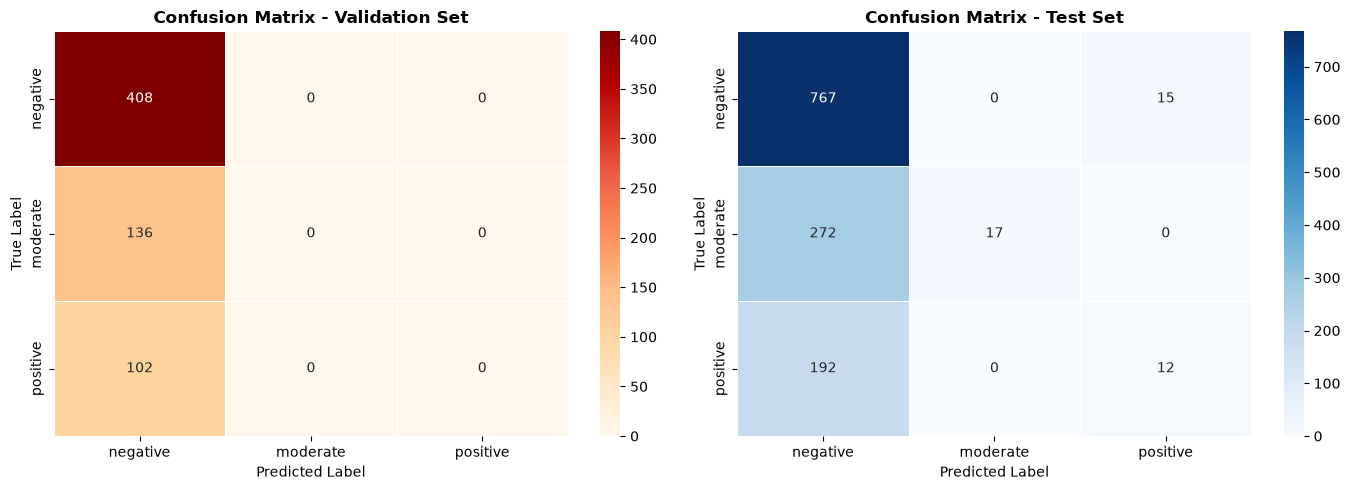

  FINAL ERROR REPORT - class-weighted bagged tree ensemble (v2)
  Split          Samples         Loss     Accuracy        Error
  --------------------------------------------------------------------
  Training         5,066       0.0715     100.00%        0.00%
  Validation         646       0.8628      63.16%       36.84%
  Test             1,275       0.9221      62.43%       37.57%


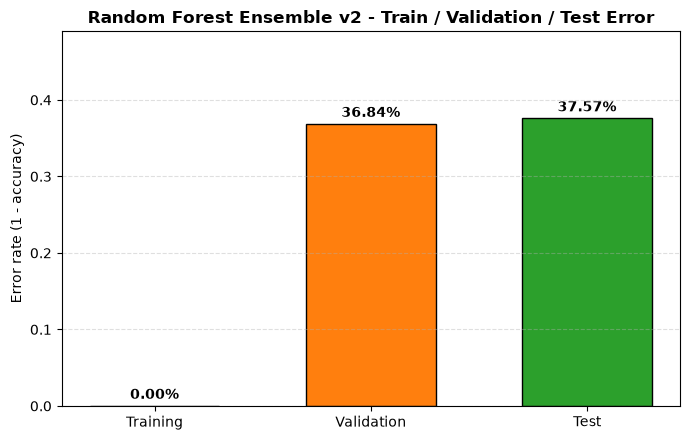

Classification CSV : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\test_classification_report_random_forest.csv
Confusion plot     : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\confusion_matrices_random_forest.png
Error report CSV   : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\final_error_report_random_forest.csv
Error report plot  : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\final_error_report_random_forest.png


In [7]:
print('Test Set — Classification Report')
print('-' * 60)
print(classification_report(
    y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0
))
print('Real-only Test Set — Classification Report')
print('-' * 60)
print(classification_report(
    test_real_y, test_real_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0
))

classification_report_df = pd.DataFrame(classification_report(
    y_test, test_predictions, labels=np.arange(len(CLASS_NAMES)),
    target_names=CLASS_NAMES, zero_division=0, output_dict=True
)).T
classification_report_path = OUTPUT_DIR / 'test_classification_report_random_forest.csv'
classification_report_df.to_csv(classification_report_path)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, predictions, labels, title, colour_map in [
    (axes[0], val_predictions, y_val, 'Confusion Matrix - Validation Set', 'OrRd'),
    (axes[1], test_predictions, y_test, 'Confusion Matrix - Test Set', 'Blues'),
]:
    matrix = confusion_matrix(labels, predictions, labels=np.arange(len(CLASS_NAMES)))
    sns.heatmap(matrix, annot=True, fmt='d', cmap=colour_map,
                xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, linewidths=0.5, ax=ax)
    ax.set_title(title, fontweight='bold')
    ax.set_xlabel('Predicted Label')
    ax.set_ylabel('True Label')
plt.tight_layout()
confusion_path = OUTPUT_DIR / 'confusion_matrices_random_forest.png'
plt.savefig(confusion_path, dpi=150, bbox_inches='tight')
plt.show()

train_loss = log_loss(y_trainval, train_probabilities, labels=np.arange(len(CLASS_NAMES)))
train_accuracy = accuracy_score(y_trainval, train_predictions)
val_loss = log_loss(y_val, val_probabilities, labels=np.arange(len(CLASS_NAMES)))
val_accuracy = accuracy_score(y_val, val_predictions)
report_rows = [
    ('Training', len(y_trainval), train_loss, train_accuracy, 1 - train_accuracy),
    ('Validation', len(y_val), val_loss, val_accuracy, 1 - val_accuracy),
    ('Test', len(y_test), test_log_loss, test_accuracy, 1 - test_accuracy),
]

print('=' * 74)
print('  FINAL ERROR REPORT - class-weighted bagged tree ensemble (v2)')
print('=' * 74)
print(f'  {"Split":<12}{"Samples":>10}{"Loss":>13}{"Accuracy":>13}{"Error":>13}')
print('  ' + '-' * 68)
for split_name, sample_count, loss_value, accuracy_value, error_value in report_rows:
    print(f'  {split_name:<12}{sample_count:>10,}{loss_value:>13.4f}'
          f'{accuracy_value:>12.2%}{error_value:>13.2%}')
print('=' * 74)

final_error_df = pd.DataFrame(report_rows, columns=['split', 'samples', 'loss', 'accuracy', 'error'])
final_error_csv = OUTPUT_DIR / 'final_error_report_random_forest.csv'
final_error_df.to_csv(final_error_csv, index=False)

fig, ax = plt.subplots(figsize=(7, 4.5))
bars = ax.bar(final_error_df['split'], final_error_df['error'],
              color=['#1f77b4', '#ff7f0e', '#2ca02c'], edgecolor='black', width=0.6)
for bar, error_rate in zip(bars, final_error_df['error']):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.005,
            f'{error_rate:.2%}', ha='center', va='bottom', fontweight='bold')
ax.set_ylabel('Error rate (1 - accuracy)')
ax.set_title('Random Forest Ensemble v2 - Train / Validation / Test Error', fontweight='bold')
ax.set_ylim(0, max(final_error_df['error']) * 1.25 + 0.02)
ax.grid(axis='y', linestyle='--', alpha=0.4)
plt.tight_layout()
final_error_png = OUTPUT_DIR / 'final_error_report_random_forest.png'
plt.savefig(final_error_png, dpi=150, bbox_inches='tight')
plt.show()

print(f'Classification CSV : {classification_report_path}')
print(f'Confusion plot     : {confusion_path}')
print(f'Error report CSV   : {final_error_csv}')
print(f'Error report plot  : {final_error_png}')

## 8. Misclassified image reports

Both CSV files contain the image name, full path, subject ID, true/predicted labels,
confidence, and all class probabilities.

Validation misclassified: 238/646
Validation CSV          : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\val_misclassified_random_forest.csv
Test misclassified      : 479/1,275
Test CSV                : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\misclassified_images_random_forest.csv


,split,split_index,image_name,image_path,image_id,image_type,true_label,predicted_label,error_type,confidence,probability_negative,probability_moderate,probability_positive
0,test,0,img114_autocontrast.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.706667,0.706667,0.193333,0.100000
1,test,1,img114_brightness_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.706667,0.706667,0.201667,0.091667
2,test,2,img114_brightness_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.726667,0.726667,0.183333,0.090000
3,test,3,img114_color_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.685000,0.685000,0.226667,0.088333
4,test,4,img114_color_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.723333,0.723333,0.191667,0.085000
5,test,5,img114_contrast_down.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.698333,0.698333,0.205000,0.096667
6,test,6,img114_contrast_up.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.711667,0.711667,0.201667,0.086667
7,test,7,img114_edge_enhance.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.696667,0.696667,0.211667,0.091667
8,test,8,img114_equalize.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.716667,0.716667,0.203333,0.080000
9,test,9,img114_gaussian_blur.jpeg,D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125...,114,augmented,moderate,negative,moderate -> negative,0.700000,0.700000,0.213333,0.086667


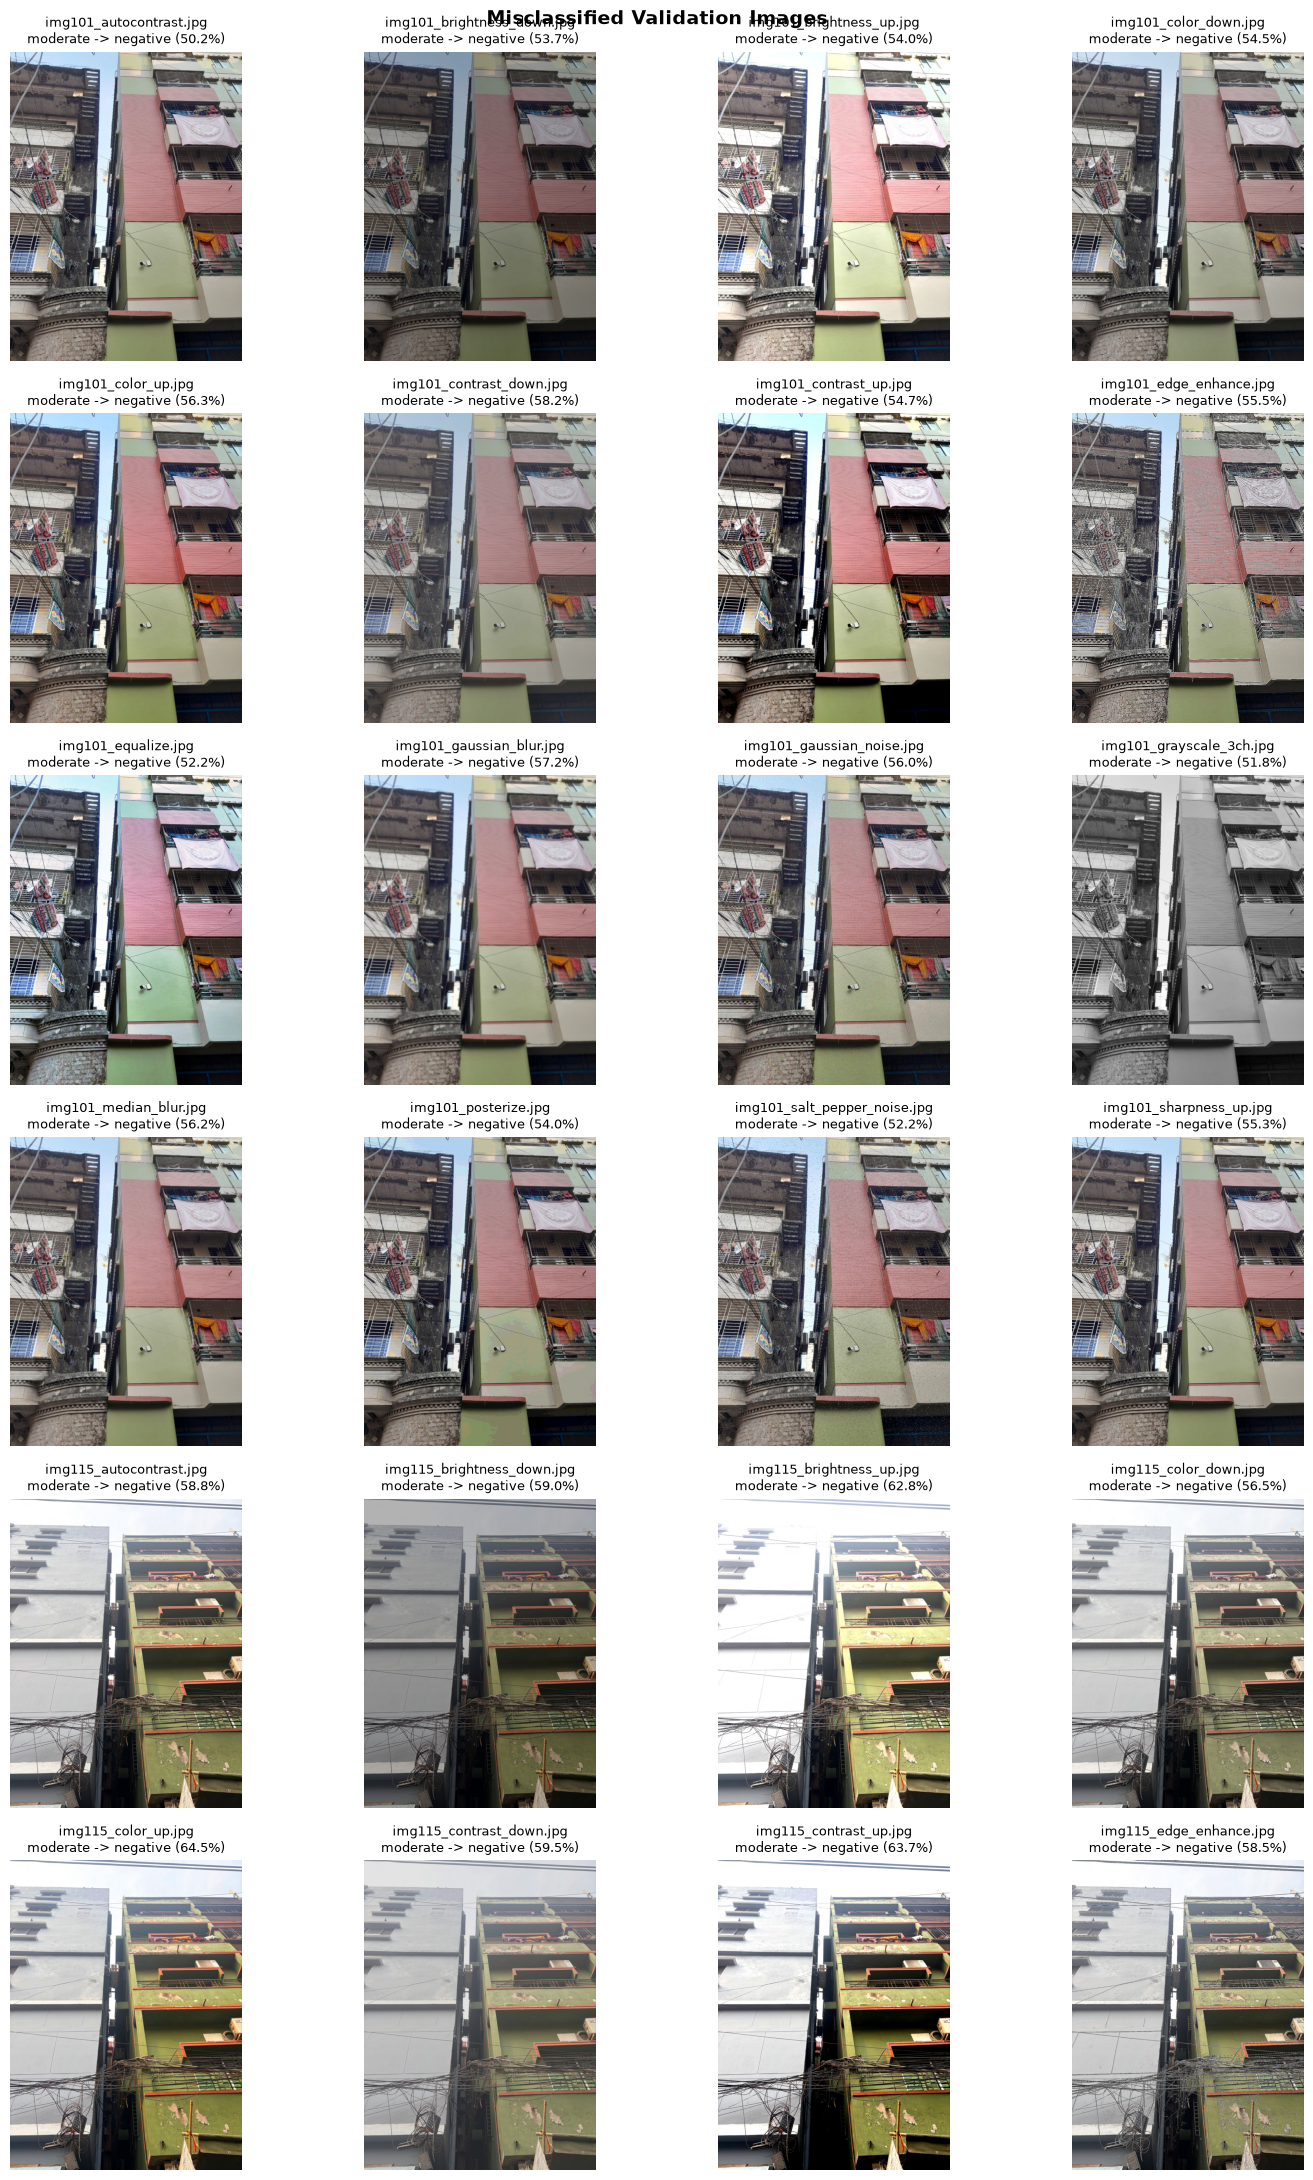

In [8]:
def build_misclassified_table(labels, predictions, probabilities, groups, paths, split_name):
    indices = np.flatnonzero(predictions != labels)
    rows = []
    for index in indices:
        path = Path(paths[index])
        image_type = 'augmented' if is_augmented_path(path) else 'real'
        row = {
            'split': split_name, 'split_index': int(index), 'image_name': path.name,
            'image_path': str(path), 'image_id': int(groups[index]), 'image_type': image_type,
            'true_label': CLASS_NAMES[int(labels[index])],
            'predicted_label': CLASS_NAMES[int(predictions[index])],
            'error_type': f'{CLASS_NAMES[int(labels[index])]} -> {CLASS_NAMES[int(predictions[index])]}',
            'confidence': float(probabilities[index, predictions[index]]),
        }
        for class_index, class_name in enumerate(CLASS_NAMES):
            row[f'probability_{class_name}'] = float(probabilities[index, class_index])
        rows.append(row)
    return pd.DataFrame(rows)

val_misclassified_df = build_misclassified_table(
    y_val, val_predictions, val_probabilities, val_groups, val_paths, 'validation')
test_misclassified_df = build_misclassified_table(
    y_test, test_predictions, test_probabilities, test_groups, test_paths, 'test')
val_misclassified_df.to_csv(VAL_MISCLASSIFIED_CSV, index=False)
test_misclassified_df.to_csv(TEST_MISCLASSIFIED_CSV, index=False)

print(f'Validation misclassified: {len(val_misclassified_df):,}/{len(y_val):,}')
print(f'Validation CSV          : {VAL_MISCLASSIFIED_CSV}')
print(f'Test misclassified      : {len(test_misclassified_df):,}/{len(y_test):,}')
print(f'Test CSV                : {TEST_MISCLASSIFIED_CSV}')
display(test_misclassified_df.head(20))

MAX_ERRORS_TO_DISPLAY = 24
display_rows = val_misclassified_df.head(MAX_ERRORS_TO_DISPLAY)
if len(display_rows):
    columns = 4
    rows = int(np.ceil(len(display_rows) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(15, 3.7 * rows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, display_rows.iterrows()):
        with Image.open(row['image_path']) as image:
            ax.imshow(image.convert('RGB'))
        ax.set_title(f"{row['image_name']}\n{row['true_label']} -> {row['predicted_label']} "
                     f"({row['confidence']:.1%})", fontsize=9)
        ax.axis('off')
    for ax in axes[len(display_rows):]:
        ax.axis('off')
    fig.suptitle('Misclassified Validation Images', fontsize=14, fontweight='bold')
    plt.tight_layout()
    validation_grid_path = OUTPUT_DIR / 'val_misclassified_grid_random_forest.png'
    plt.savefig(validation_grid_path, dpi=130, bbox_inches='tight')
    plt.show()

## 9. Bias-variance analysis

Individual trees (trained on the training split only) are treated as ensemble members
and their validation probability predictions are decomposed into squared bias and
variance.

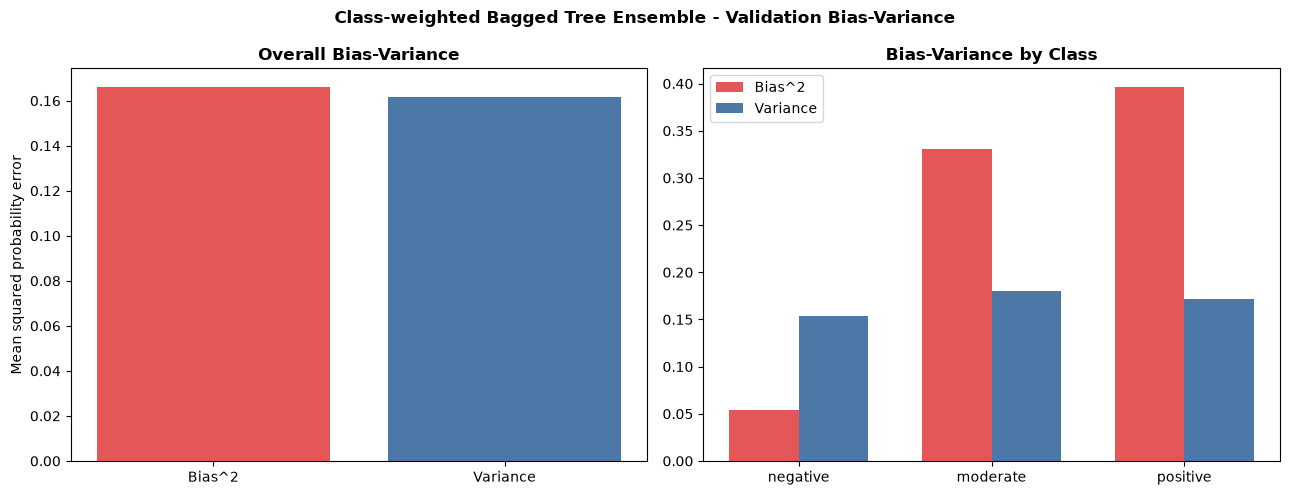

Bias^2: 0.166053 | Variance: 0.161828
Graph saved to: D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\bias_variance_random_forest.png


In [9]:
member_probabilities = bias_member_probabilities
member_weights = bias_member_weights
mean_probabilities = np.average(member_probabilities, axis=0, weights=member_weights)
one_hot = np.eye(len(CLASS_NAMES))[y_val]
bias_squared_samples = np.mean((mean_probabilities - one_hot) ** 2, axis=1)
per_member_squared_distance = np.mean(
    (member_probabilities - mean_probabilities[None, :, :]) ** 2, axis=2)
variance_samples = np.average(per_member_squared_distance, axis=0, weights=member_weights)

overall_bias_squared = float(bias_squared_samples.mean())
overall_variance = float(variance_samples.mean())
class_bias = [bias_squared_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]
class_variance = [variance_samples[y_val == index].mean() for index in range(len(CLASS_NAMES))]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].bar(['Bias^2', 'Variance'], [overall_bias_squared, overall_variance],
            color=['#e45756', '#4c78a8'])
axes[0].set_title('Overall Bias-Variance', fontweight='bold')
axes[0].set_ylabel('Mean squared probability error')

positions = np.arange(len(CLASS_NAMES))
width = 0.36
axes[1].bar(positions - width/2, class_bias, width, label='Bias^2', color='#e45756')
axes[1].bar(positions + width/2, class_variance, width, label='Variance', color='#4c78a8')
axes[1].set_xticks(positions)
axes[1].set_xticklabels(CLASS_NAMES)
axes[1].set_title('Bias-Variance by Class', fontweight='bold')
axes[1].legend()
fig.suptitle('Class-weighted Bagged Tree Ensemble - Validation Bias-Variance', fontweight='bold')
plt.tight_layout()
plt.savefig(BIAS_VARIANCE_PNG, dpi=160, bbox_inches='tight')
plt.show()
print(f'Bias^2: {overall_bias_squared:.6f} | Variance: {overall_variance:.6f}')
print(f'Graph saved to: {BIAS_VARIANCE_PNG}')

## 10. Ensemble feature importance

,embedding_dimension,importance
0,resnet50_1328,0.005406
1,resnet50_851,0.005267
2,resnet50_116,0.004031
3,resnet50_1829,0.003617
4,resnet50_911,0.003368
5,resnet50_974,0.003354
6,resnet50_923,0.003337
7,resnet50_1815,0.003003
8,resnet50_559,0.002981
9,resnet50_665,0.002808


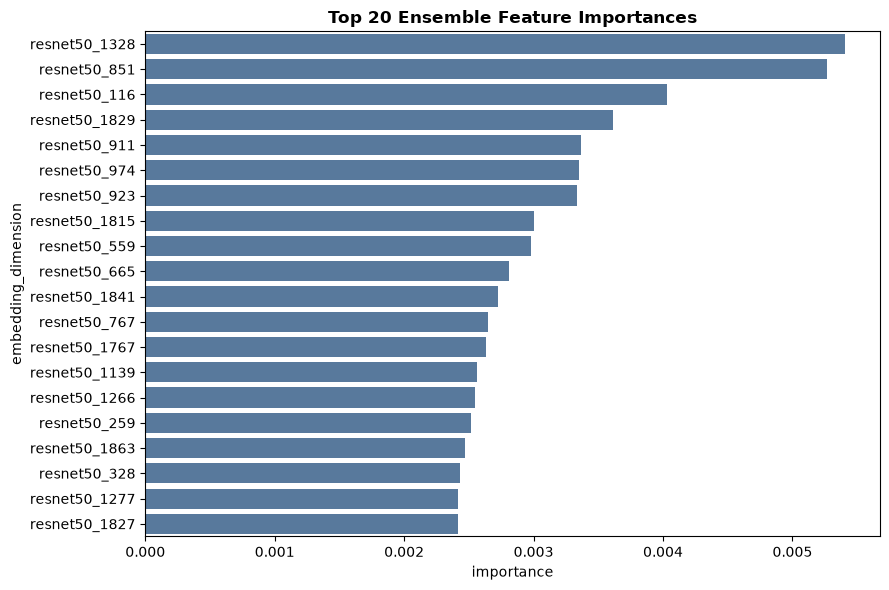

In [10]:
normalized_weights = np.asarray(selected_weights, dtype=float)
normalized_weights /= normalized_weights.sum()
ensemble_importance = np.average(
    np.stack([model.feature_importances_ for model in final_models]),
    axis=0, weights=normalized_weights)
top_indices = np.argsort(ensemble_importance)[-20:][::-1]
importance_df = pd.DataFrame({
    'embedding_dimension': [f'{BACKBONE_NAME}_{index}' for index in top_indices],
    'importance': ensemble_importance[top_indices],
})
display(importance_df)
plt.figure(figsize=(9, 6))
sns.barplot(data=importance_df, y='embedding_dimension', x='importance', color='#4c78a8')
plt.title('Top 20 Ensemble Feature Importances', fontweight='bold')
plt.tight_layout()
feature_importance_path = OUTPUT_DIR / 'feature_importance_random_forest.png'
plt.savefig(feature_importance_path, dpi=150, bbox_inches='tight')
plt.show()

## 11. Save the model and inference helper

In [11]:
artifact = {
    'component_models': final_models,
    'voting_weights': np.asarray(selected_weights),
    'selected_configs': selected_configs,
    'class_names': CLASS_NAMES,
    'backbone': BACKBONE_NAME,
    'feature_extractor': 'ImageNet pretrained ResNet50 (V2) frozen 2048-D L2-normalized embedding',
    'balancing': 'class_weight=balanced_subsample on full training set',
    'label_source': str(label_source),
    'test_accuracy': float(test_accuracy),
    'test_balanced_accuracy': float(test_balanced_accuracy),
    'test_macro_f1': float(test_macro_f1),
    'test_real_accuracy': float(test_real_accuracy),
    'test_real_balanced_accuracy': float(test_real_balanced_accuracy),
    'test_real_macro_f1': float(test_real_macro_f1),
    'test_subject_metrics': test_subject_metrics,
    'reference_test_accuracy': REFERENCE_TEST_ACCURACY,
    'reference_test_macro_f1': REFERENCE_TEST_MACRO_F1,
}
with open(MODEL_PATH, 'wb') as file:
    pickle.dump(artifact, file)

print(f'Model saved to              : {MODEL_PATH}')
print(f'Test accuracy               : {test_accuracy:.4f}')
print(f'Test macro-F1               : {test_macro_f1:.4f}')
print(f'Real accuracy vs old RF     : {test_real_accuracy - REFERENCE_TEST_ACCURACY:+.4f}')
print(f'Real macro-F1 vs old RF     : {test_real_macro_f1 - REFERENCE_TEST_MACRO_F1:+.4f}')

def load_artifact(model_path=MODEL_PATH):
    with open(model_path, 'rb') as file:
        return pickle.load(file)

def predict_image(image_path, trained_artifact):
    with Image.open(image_path) as image:
        tensor = image_transform(image.convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.inference_mode():
        if DEVICE.type == 'cuda':
            with torch.autocast(device_type='cuda', dtype=torch.float16):
                embedding = resnet_backbone(tensor)
        else:
            embedding = resnet_backbone(tensor)
        embedding = F.normalize(embedding.float(), p=2, dim=1).cpu().numpy()
    probabilities = ensemble_predict_proba(
        trained_artifact['component_models'], trained_artifact['voting_weights'], embedding)[0]
    predicted_index = int(np.argmax(probabilities))
    return {
        'prediction': trained_artifact['class_names'][predicted_index],
        'confidence': float(probabilities[predicted_index]),
        'probabilities': dict(zip(trained_artifact['class_names'], probabilities.astype(float))),
    }

# Example:
# trained_artifact = load_artifact()
# print(predict_image(PROJECT_ROOT / 'new_image.jpg', trained_artifact))

Model saved to              : D:\Downloads\DUCSE Documents\4-1\Mine\CSE-4125 Introduction to Machine Learning\Lab\Final Project\taining files\Random_Forest\f2\rajuk_random_forest_v2.pkl
Test accuracy               : 0.6243
Test macro-F1               : 0.3257
Real accuracy vs old RF     : +0.0450
Real macro-F1 vs old RF     : +0.2244
